<a href="https://colab.research.google.com/github/scribenaz/CPP528/blob/main/Exercise_18_ex_9_1_stocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shriver Smith  
Exercise 9-1 Analyze time-series Data  
Class: AIM111 - Introduction to Data Science  
Date: October 27, 2026  

# Exercise 9-1: Analyze time-series data

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
stockData = pd.read_pickle('stocks.pkl')
stockData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    253 non-null    datetime64[ns]
 1   Open    253 non-null    float64       
 2   High    253 non-null    float64       
 3   Low     253 non-null    float64       
 4   Close   253 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 10.0 KB


In [3]:
# display the first five rows

In [14]:
stockData.head()

,Date,Open,High,Low,Close
0,2020-01-02,74.059998,75.150002,73.797501,75.087502
1,2020-01-03,74.287498,75.144997,74.125000,74.357498
2,2020-01-06,73.447502,74.989998,73.187500,74.949997
3,2020-01-07,74.959999,75.224998,74.370003,74.597504
4,2020-01-08,74.290001,76.110001,74.290001,75.797501


## Generate date ranges

In [4]:
# generate a daterange for every other day in the year 2020

In [15]:
pd.date_range(start='2020-01-01', end='2020-12-31', freq='2D')

DatetimeIndex(['2020-01-01', '2020-01-03', '2020-01-05', '2020-01-07',
               '2020-01-09', '2020-01-11', '2020-01-13', '2020-01-15',
               '2020-01-17', '2020-01-19',
               ...
               '2020-12-12', '2020-12-14', '2020-12-16', '2020-12-18',
               '2020-12-20', '2020-12-22', '2020-12-24', '2020-12-26',
               '2020-12-28', '2020-12-30'],
              dtype='datetime64[ns]', length=183, freq='2D')

In [5]:
# generate a daterange for every 3 hours in 2020

In [18]:
pd.date_range(start='2020-01-01', end='2020-12-31 23:59:59', freq='3h')

DatetimeIndex(['2020-01-01 00:00:00', '2020-01-01 03:00:00',
               '2020-01-01 06:00:00', '2020-01-01 09:00:00',
               '2020-01-01 12:00:00', '2020-01-01 15:00:00',
               '2020-01-01 18:00:00', '2020-01-01 21:00:00',
               '2020-01-02 00:00:00', '2020-01-02 03:00:00',
               ...
               '2020-12-30 18:00:00', '2020-12-30 21:00:00',
               '2020-12-31 00:00:00', '2020-12-31 03:00:00',
               '2020-12-31 06:00:00', '2020-12-31 09:00:00',
               '2020-12-31 12:00:00', '2020-12-31 15:00:00',
               '2020-12-31 18:00:00', '2020-12-31 21:00:00'],
              dtype='datetime64[ns]', length=2928, freq='3h')

In [6]:
# generate a date range for every other Friday in 2020

In [19]:
pd.date_range(start='2020-01-01', end='2020-12-31 23:59:59', freq='2W-FRI')

DatetimeIndex(['2020-01-03', '2020-01-17', '2020-01-31', '2020-02-14',
               '2020-02-28', '2020-03-13', '2020-03-27', '2020-04-10',
               '2020-04-24', '2020-05-08', '2020-05-22', '2020-06-05',
               '2020-06-19', '2020-07-03', '2020-07-17', '2020-07-31',
               '2020-08-14', '2020-08-28', '2020-09-11', '2020-09-25',
               '2020-10-09', '2020-10-23', '2020-11-06', '2020-11-20',
               '2020-12-04', '2020-12-18'],
              dtype='datetime64[ns]', freq='2W-FRI')

## Reindex the data

In [7]:
# set an index on the date column for the stock data

In [20]:
stockData = stockData.set_index('Date')
stockData.head()

,Open,High,Low,Close
Date,,,,
2020-01-02,74.059998,75.150002,73.797501,75.087502
2020-01-03,74.287498,75.144997,74.125000,74.357498
2020-01-06,73.447502,74.989998,73.187500,74.949997
2020-01-07,74.959999,75.224998,74.370003,74.597504
2020-01-08,74.290001,76.110001,74.290001,75.797501


In [8]:
# reindex the data so the data contains only Fridays
# and assign the result to a variable called stockDataFridays

In [21]:
stockDataFridays = stockData.reindex(pd.date_range(start='2020-01-01', end='2020-12-31', freq='W-FRI'))
stockDataFridays.head()

,Open,High,Low,Close
2020-01-03,74.287498,75.144997,74.125000,74.357498
2020-01-10,77.650002,78.167503,77.062500,77.582497
2020-01-17,79.067497,79.684998,78.750000,79.682503
2020-01-24,80.062500,80.832497,79.379997,79.577499
2020-01-31,80.232498,80.669998,77.072502,77.377502


In [26]:
stockDataFridays.shape


(52, 4)

In [25]:
stockDataFridays.Close.isna().sum()

np.int64(3)

In [9]:
# use Pandas to plot the Close column of the reindexed data

<Axes: >

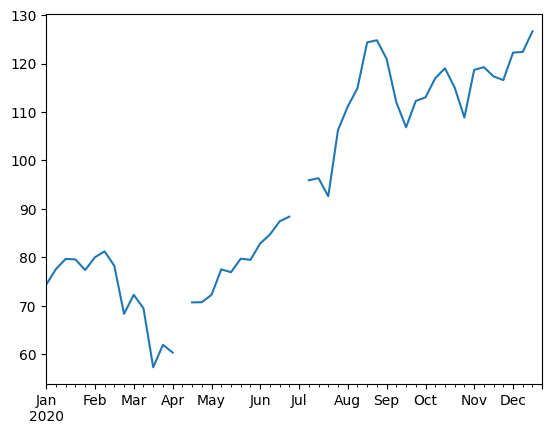

In [27]:
stockDataFridays.Close.plot()

In [28]:
stockDataFridays[stockDataFridays.Close.isna()]
# expected Market Close Days explains the gaps in the plot

,Open,High,Low,Close
2020-04-10,NaN,NaN,NaN,NaN
2020-07-03,NaN,NaN,NaN,NaN
2020-12-25,NaN,NaN,NaN,NaN


## Resample the data

In [10]:
# downsample the data to a monthly frequency

In [30]:
stockDataDown = stockData.resample('ME').mean()
stockDataDown.head()

,Open,High,Low,Close
Date,,,,
2020-01-31,77.792738,78.581547,77.207857,77.979048
2020-02-29,77.578421,78.813158,76.681579,77.817631
2020-03-31,65.268410,67.423181,63.711591,65.611023
2020-04-30,67.952857,68.945357,67.021072,68.096547
2020-05-31,77.221375,78.312875,76.595250,77.496376


In [11]:
# use Pandas to plot the Close column of the resampled data

<Axes: xlabel='Date'>

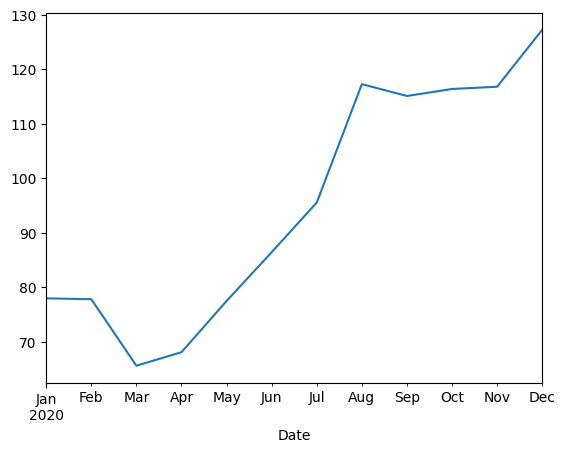

In [31]:
stockDataDown.Close.plot()

## Compute a rolling window

In [34]:
# compute a 2 week rolling average for the Close column
# set the min_periods to 1 and assign the data to a variable called stocksRolling

In [35]:
stocksRolling = stockData['Close'].rolling(window=14, min_periods=1).mean()
stocksRolling.head()


,Close
Date,
2020-01-02,75.087502
2020-01-03,74.722500
2020-01-06,74.798332
2020-01-07,74.748125
2020-01-08,74.958000


In [36]:
# use Pandas to plot the Close column of the rolling data

<Axes: xlabel='Date'>

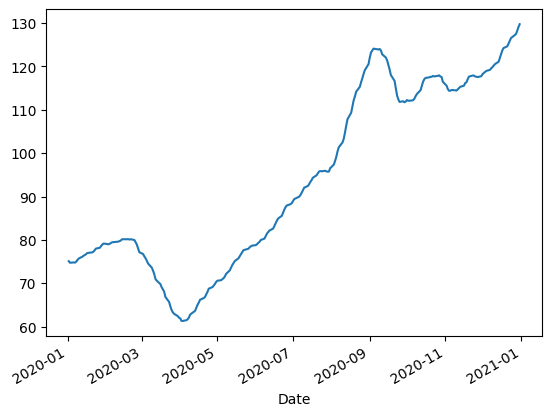

In [38]:
stocksRolling.plot()